In [2]:

import os
import subprocess

def check_hardware():
    print("=" * 45)
    print("COLAB HARDWARE")
    print("=" * 45)

    # GPU
    try:
        gpu = subprocess.check_output(
            ["nvidia-smi", "--query-gpu=name,memory.total",
             "--format=csv,noheader"],
            stderr=subprocess.DEVNULL
        ).decode().strip()

        print(f"GPU: {gpu}")
    except (FileNotFoundError, subprocess.CalledProcessError):
        print("GPU: Not detected")

    # TPU
    tpu = os.environ.get("COLAB_TPU_ADDR")
    print(f"TPU: {tpu if tpu else 'Not detected'}")

    # CPU
    print(f"CPU cores: {os.cpu_count()}")

    print("=" * 45)

check_hardware()


COLAB HARDWARE
GPU: Not detected
TPU: Not detected
CPU cores: 12


In [3]:
import os, time, copy, random
import numpy as np
import torch
import matplotlib.pyplot as plt

SEED = 551

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cpu


# TASK 1: Acquire the data

In [4]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

DATA_ROOT = './data'
NUM_CLASSES = 10
CLASS_NAMES = datasets.FashionMNIST.classes

train_full = datasets.FashionMNIST(root=DATA_ROOT, train=True, download=True, transform=transforms.ToTensor())
test_full = datasets.FashionMNIST(root=DATA_ROOT, train=False, download=True, transform=transforms.ToTensor())

# split train in train and val with a seed so every model use the same split
def split_indices(n, train_ratio=0.8, seed=SEED):
    perm = torch.randperm(n, generator=torch.Generator().manual_seed(seed)).tolist()
    n_train = int(train_ratio * n)
    return perm[:n_train], perm[n_train:]

train_idx, val_idx = split_indices(len(train_full))
print(f"train: {len(train_idx)} val: {len(val_idx)} test: {len(test_full)}")

# mean and std only on train so no leak from val and test
train_pixels = train_full.data[train_idx].float() / 255.0
mean = train_pixels.mean().item()
std = train_pixels.std().item()
print(f"mean = {mean:.4f} std = {std:.4f}")

# flatten 28x28 to 784 and normalize for the mlp
def to_numpy(images, labels, normalize=True):
    X = images.float().reshape(len(images), -1)
    if normalize:
        X = (X / 255.0 - mean) / std
    return X.numpy().astype(np.float32), labels.numpy().astype(np.int64)

X_train, y_train = to_numpy(train_full.data[train_idx], train_full.targets[train_idx])
X_val, y_val = to_numpy(train_full.data[val_idx], train_full.targets[val_idx])
X_test, y_test = to_numpy(test_full.data, test_full.targets)

# raw pixels 0-255 for 3.4
X_train_raw, _ = to_numpy(train_full.data[train_idx], train_full.targets[train_idx], normalize=False)
X_val_raw, _ = to_numpy(train_full.data[val_idx], train_full.targets[val_idx], normalize=False)
X_test_raw, _ = to_numpy(test_full.data, test_full.targets, normalize=False)
print("X_train:", X_train.shape, "X_test:", X_test.shape)

# transforms for the dataloaders (augmentation and cnn)
normalize_tf = transforms.Normalize((mean,), (std,))
flatten_tf = transforms.Lambda(torch.flatten)

# same augmentation for 3.5 3.7 and 3.8
augment_ops = [
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
]
mlp_eval_transform = transforms.Compose([transforms.ToTensor(), normalize_tf, flatten_tf])
mlp_train_transform = transforms.Compose(augment_ops + [transforms.ToTensor(), normalize_tf, flatten_tf])

# augmentation only on train never on val and test
def make_fmnist_splits(train_transform, eval_transform):
    train_ds = datasets.FashionMNIST(DATA_ROOT, train=True, download=True, transform=train_transform)
    eval_ds = datasets.FashionMNIST(DATA_ROOT, train=True, download=True, transform=eval_transform)
    test_ds = datasets.FashionMNIST(DATA_ROOT, train=False, download=True, transform=eval_transform)
    return Subset(train_ds, train_idx), Subset(eval_ds, val_idx), test_ds

train: 48000 val: 12000 test: 10000
mean = 0.2858 std = 0.3530
X_train: (48000, 784) X_test: (10000, 784)


# TASK 2: Implement a Multilayer Perceptron

In [5]:
# activations and their derivatives
def relu(z): return np.maximum(0, z)
def relu_der(z): return (z > 0).astype(z.dtype)
def leaky_relu(z, a=0.01): return np.where(z > 0, z, a * z)
def leaky_relu_der(z, a=0.01): return np.where(z > 0, 1.0, a).astype(z.dtype)
def tanh(z): return np.tanh(z)
def tanh_der(z): return 1.0 - np.tanh(z) ** 2

ACTIVATIONS = {'relu': (relu, relu_der), 'leaky_relu': (leaky_relu, leaky_relu_der), 'tanh': (tanh, tanh_der)}

def softmax(z):
    z = z - z.max(axis=1, keepdims=True)  # for stability
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def one_hot(y, num_classes):
    Y = np.zeros((len(y), num_classes), dtype=np.float32)
    Y[np.arange(len(y)), y] = 1
    return Y

def evaluate_acc(y_true, y_pred):
    y_pred = np.asarray(y_pred)
    if y_pred.ndim == 2:  # if we get probabilities take the argmax
        y_pred = y_pred.argmax(axis=1)
    return np.mean(y_pred == np.asarray(y_true))


# mini batch sgd (momentum 0 = plain sgd)
class GradientDescent:
    def __init__(self, learning_rate=0.05, momentum=0.0):
        self.learning_rate = learning_rate
        self.momentum = momentum
        self.velocity = None

    def step(self, params, grads):
        if self.velocity is None:
            self.velocity = [np.zeros_like(p) for p in params]
        for p, g, v in zip(params, grads, self.velocity):
            v *= self.momentum
            v -= self.learning_rate * g
            p += v


class MLP:
    # activation: 'relu' 'leaky_relu' or 'tanh'
    # num_hidden = 0 means no hidden layer
    # hidden_units is an int or a list like [256, 256]
    def __init__(self, activation='relu', num_hidden=2, hidden_units=256,
                 input_dim=784, num_classes=10, l1=0.0, l2=0.0, seed=SEED):
        self.activation_name = activation
        if activation is None:
            self.act, self.act_der = None, None
        else:
            self.act, self.act_der = ACTIVATIONS[activation]
        if isinstance(hidden_units, int):
            hidden_units = [hidden_units] * num_hidden
        assert len(hidden_units) == num_hidden
        self.num_hidden = num_hidden
        self.layer_sizes = [input_dim] + list(hidden_units) + [num_classes]
        self.num_classes = num_classes
        self.l1, self.l2 = l1, l2
        self.history = {}

        # he init for relu and xavier for tanh and the output layer
        rng = np.random.default_rng(seed)
        self.weights, self.biases = [], []
        n_layers = len(self.layer_sizes) - 1
        for l, (fan_in, fan_out) in enumerate(zip(self.layer_sizes[:-1], self.layer_sizes[1:])):
            gain = 1.0 if (l == n_layers - 1 or activation == 'tanh') else 2.0
            W = rng.standard_normal((fan_in, fan_out)) * np.sqrt(gain / fan_in)
            self.weights.append(W.astype(np.float32))
            self.biases.append(np.zeros(fan_out, dtype=np.float32))

    def _forward(self, X):
        a, z = [X], []
        for W, b in zip(self.weights[:-1], self.biases[:-1]):
            z.append(a[-1] @ W + b)
            a.append(self.act(z[-1]))
        probs = softmax(a[-1] @ self.weights[-1] + self.biases[-1])
        return a, z, probs

    def _backward(self, a, z, probs, Y):
        N = Y.shape[0]
        grads_W = [None] * len(self.weights)
        grads_b = [None] * len(self.biases)
        delta = (probs - Y) / N  # softmax + cross entropy
        for l in reversed(range(len(self.weights))):
            grads_W[l] = a[l].T @ delta
            grads_b[l] = delta.sum(axis=0)
            if self.l2:
                grads_W[l] += self.l2 * self.weights[l]
            if self.l1:
                grads_W[l] += self.l1 * np.sign(self.weights[l])
            if l > 0:  # go back to the previous layer
                delta = (delta @ self.weights[l].T) * self.act_der(z[l - 1])
        return grads_W, grads_b

    def loss(self, X, y):
        probs = self.predict_proba(X)
        ce = -np.mean(np.log(probs[np.arange(len(y)), y] + 1e-12))
        penalty = sum(0.5 * self.l2 * np.sum(W ** 2) + self.l1 * np.sum(np.abs(W)) for W in self.weights)
        return ce + penalty

    @staticmethod
    def _batches(X, y, batch_size, rng):
        if y is None:  # X is a dataloader
            for xb, yb in X:
                yield xb.reshape(len(xb), -1).numpy().astype(np.float32), yb.numpy()
        else:
            idx = rng.permutation(len(X))
            for s in range(0, len(X), batch_size):
                b = idx[s:s + batch_size]
                yield X[b], y[b]

    def _eval(self, X, y):
        probs = self.predict_proba(X)
        ce = -np.mean(np.log(probs[np.arange(len(y)), y] + 1e-12))
        return ce, evaluate_acc(y, probs)

    # X y numpy arrays or X a dataloader and y=None (for augmentation)
    # saves train val test acc every epoch and keeps the weights of the best val epoch
    def fit(self, X, y=None, learning_rate=0.05, epochs=20, batch_size=64, optimizer=None,
            X_val=None, y_val=None, X_test=None, y_test=None, name=None, verbose=True, seed=SEED, es=False, patience=5):
        optimizer = optimizer or GradientDescent(learning_rate)
        rng = np.random.default_rng(seed)
        params = self.weights + self.biases
        hist = {k: [] for k in ['train_loss', 'train_acc', 'val_loss', 'val_acc', 'test_loss', 'test_acc', 'epoch_time']}
        best_val, best_epoch, best_params = -np.inf, 0, None
        wait = 0  # for early stopping

        for epoch in range(1, epochs + 1):
            t0 = time.time()
            n_seen, loss_sum, correct = 0, 0.0, 0
            for Xb, yb in self._batches(X, y, batch_size, rng):
                a, z, probs = self._forward(Xb)
                gW, gb = self._backward(a, z, probs, one_hot(yb, self.num_classes))
                optimizer.step(params, gW + gb)
                loss_sum += -np.log(probs[np.arange(len(yb)), yb] + 1e-12).sum()
                correct += (probs.argmax(axis=1) == yb).sum()
                n_seen += len(yb)
            hist['epoch_time'].append(time.time() - t0)

            if y is not None:
                tr_loss, tr_acc = self._eval(X, y)
            else:  # with dataloader we use the running acc on the augmented images
                tr_loss, tr_acc = loss_sum / n_seen, correct / n_seen
            hist['train_loss'].append(tr_loss)
            hist['train_acc'].append(tr_acc)
            for split, (Xs, ys) in {'val': (X_val, y_val), 'test': (X_test, y_test)}.items():
                l, acc = self._eval(Xs, ys) if Xs is not None else (np.nan, np.nan)
                hist[f'{split}_loss'].append(l)
                hist[f'{split}_acc'].append(acc)

            score = hist['val_acc'][-1] if X_val is not None else tr_acc
            if score > best_val:
                best_val, best_epoch = score, epoch
                best_params = [p.copy() for p in params]
                wait = 0
            else:
                wait += 1
            if verbose:
                print(f"epoch {epoch:3d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
                      f"val acc {hist['val_acc'][-1]:.4f} | test acc {hist['test_acc'][-1]:.4f} | "
                      f"{hist['epoch_time'][-1]:.1f}s")
            if not np.isfinite(tr_loss):
                print("loss is nan or inf so we stop")
                break
            if es and wait >= patience:
                break

        for p, best in zip(params, best_params):
            p[...] = best
        hist.update(name=name or f"MLP {self.layer_sizes} {self.activation_name}",
                    best_epoch=best_epoch, best_val_acc=best_val,
                    test_acc_at_best=hist['test_acc'][best_epoch - 1],
                    total_train_time=sum(hist['epoch_time']),
                    n_trainable=sum(p.size for p in params))
        self.history = hist
        return self

    def predict_proba(self, X, chunk=10000):
        return np.concatenate([self._forward(X[i:i + chunk])[2] for i in range(0, len(X), chunk)])

    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)

In [6]:
# check the backprop with finite differences (error should be very small)
def gradient_check(activation='relu', num_hidden=2, l1=0.0, l2=0.0, eps=1e-6, n=8, seed=0):
    rng = np.random.default_rng(seed)
    m = MLP(activation, num_hidden=num_hidden, hidden_units=5, input_dim=6, num_classes=3, l1=l1, l2=l2, seed=seed)
    m.weights = [W.astype(np.float64) for W in m.weights]
    m.biases = [b.astype(np.float64) + 0.1 * rng.standard_normal(b.shape) for b in m.biases]
    X, y = rng.standard_normal((n, 6)), rng.integers(0, 3, n)
    a, z, p = m._forward(X)
    gW, gb = m._backward(a, z, p, one_hot(y, 3).astype(np.float64))
    worst = 0.0
    for P, G in zip(m.weights + m.biases, gW + gb):
        num = np.zeros_like(P)
        for i in np.ndindex(P.shape):
            old = P[i]
            P[i] = old + eps; lp = m.loss(X, y)
            P[i] = old - eps; lm = m.loss(X, y)
            P[i] = old
            num[i] = (lp - lm) / (2 * eps)
        worst = max(worst, np.max(np.abs(num - G) / np.maximum(1e-8, np.abs(num) + np.abs(G))))
    return worst

for act in ['relu', 'leaky_relu', 'tanh']:
    for h in [0, 1, 2]:
        print(f"{act} hidden={h}: {gradient_check(act, h):.2e}")
print(f"relu + l2: {gradient_check('relu', 2, l2=0.1):.2e}")
print(f"relu + l1: {gradient_check('relu', 2, l1=0.1):.2e}")

relu hidden=0: 2.59e-09
relu hidden=1: 1.53e-07
relu hidden=2: 2.54e-06
leaky_relu hidden=0: 2.59e-09
leaky_relu hidden=1: 1.26e-07
leaky_relu hidden=2: 1.02e-07
tanh hidden=0: 2.59e-09
tanh hidden=1: 1.51e-07
tanh hidden=2: 2.21e-08
relu + l2: 1.89e-08
relu + l1: 3.01e-08


In [7]:
# quick test 2 epochs (the real experiments are in task 3)
demo = MLP(activation='relu', num_hidden=2, hidden_units=[256, 256])
demo.fit(X_train, y_train, learning_rate=0.05, epochs=2, batch_size=64,
         X_val=X_val, y_val=y_val, X_test=X_test, y_test=y_test)
print("test acc:", evaluate_acc(y_test, demo.predict(X_test)))

/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:77: RuntimeWarning: divide by zero encountered in matmul
  z.append(a[-1] @ W + b)
/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:77: RuntimeWarning: overflow encountered in matmul
  z.append(a[-1] @ W + b)
/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:77: RuntimeWarning: invalid value encountered in matmul
  z.append(a[-1] @ W + b)
/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:79: RuntimeWarning: divide by zero encountered in matmul
  probs = softmax(a[-1] @ self.weights[-1] + self.biases[-1])
/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:79: RuntimeWarning: overflow encountered in matmul
  probs = softmax(a[-1] @ self.weights[-1] + self.biases[-1])
/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:79: RuntimeWarning: invalid value encountered in mat

epoch   1 | train loss 0.3971 acc 0.8573 | val acc 0.8505 | test acc 0.8381 | 0.2s
epoch   2 | train loss 0.3307 acc 0.8800 | val acc 0.8688 | test acc 0.8527 | 0.2s
test acc: 0.8527


# TASK 3: Run the experiments and report
- implement l1 and l2 seperately
- apply gaussian noise and see what happens lol
- input normalization, input is just a bunch of data

3.1: Comparing 3 different MLP models

epoch   1 | train loss 0.5159 acc 0.8248 | val acc 0.8186 | test acc 0.8070 | 0.0s
epoch   2 | train loss 0.4810 acc 0.8367 | val acc 0.8283 | test acc 0.8199 | 0.0s
epoch   3 | train loss 0.4358 acc 0.8478 | val acc 0.8406 | test acc 0.8274 | 0.0s


/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:79: RuntimeWarning: divide by zero encountered in matmul
  probs = softmax(a[-1] @ self.weights[-1] + self.biases[-1])
/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:79: RuntimeWarning: overflow encountered in matmul
  probs = softmax(a[-1] @ self.weights[-1] + self.biases[-1])
/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:79: RuntimeWarning: invalid value encountered in matmul
  probs = softmax(a[-1] @ self.weights[-1] + self.biases[-1])
/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:88: RuntimeWarning: divide by zero encountered in matmul
  grads_W[l] = a[l].T @ delta
/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:88: RuntimeWarning: overflow encountered in matmul
  grads_W[l] = a[l].T @ delta
/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:88: Runt

epoch   4 | train loss 0.4448 acc 0.8476 | val acc 0.8400 | test acc 0.8292 | 0.1s
epoch   5 | train loss 0.4090 acc 0.8579 | val acc 0.8504 | test acc 0.8390 | 0.0s
epoch   6 | train loss 0.3980 acc 0.8622 | val acc 0.8534 | test acc 0.8392 | 0.1s
epoch   7 | train loss 0.4135 acc 0.8552 | val acc 0.8422 | test acc 0.8293 | 0.0s
epoch   8 | train loss 0.4362 acc 0.8553 | val acc 0.8421 | test acc 0.8332 | 0.1s
epoch   9 | train loss 0.4668 acc 0.8347 | val acc 0.8260 | test acc 0.8138 | 0.1s
epoch  10 | train loss 0.3855 acc 0.8664 | val acc 0.8512 | test acc 0.8393 | 0.0s
epoch  11 | train loss 0.3902 acc 0.8651 | val acc 0.8537 | test acc 0.8387 | 0.1s
epoch  12 | train loss 0.3890 acc 0.8659 | val acc 0.8490 | test acc 0.8386 | 0.0s
epoch  13 | train loss 0.4373 acc 0.8477 | val acc 0.8334 | test acc 0.8219 | 0.0s
epoch  14 | train loss 0.3965 acc 0.8654 | val acc 0.8491 | test acc 0.8375 | 0.1s
epoch  15 | train loss 0.3906 acc 0.8667 | val acc 0.8488 | test acc 0.8381 | 0.1s
epoc

/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:77: RuntimeWarning: divide by zero encountered in matmul
  z.append(a[-1] @ W + b)
/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:77: RuntimeWarning: overflow encountered in matmul
  z.append(a[-1] @ W + b)
/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:77: RuntimeWarning: invalid value encountered in matmul
  z.append(a[-1] @ W + b)
/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:95: RuntimeWarning: divide by zero encountered in matmul
  delta = (delta @ self.weights[l].T) * self.act_der(z[l - 1])
/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:95: RuntimeWarning: overflow encountered in matmul
  delta = (delta @ self.weights[l].T) * self.act_der(z[l - 1])
/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:95: RuntimeWarning: invalid value encountered in m

epoch   1 | train loss 0.4186 acc 0.8505 | val acc 0.8466 | test acc 0.8316 | 0.2s
epoch   2 | train loss 0.3499 acc 0.8728 | val acc 0.8642 | test acc 0.8538 | 0.1s
epoch   3 | train loss 0.3137 acc 0.8864 | val acc 0.8759 | test acc 0.8613 | 0.1s
epoch   4 | train loss 0.3144 acc 0.8855 | val acc 0.8708 | test acc 0.8580 | 0.1s
epoch   5 | train loss 0.2724 acc 0.9025 | val acc 0.8852 | test acc 0.8713 | 0.1s
epoch   6 | train loss 0.2625 acc 0.9056 | val acc 0.8853 | test acc 0.8702 | 0.1s
epoch   7 | train loss 0.2565 acc 0.9055 | val acc 0.8822 | test acc 0.8684 | 0.1s
epoch   8 | train loss 0.2347 acc 0.9154 | val acc 0.8931 | test acc 0.8773 | 0.1s
epoch   9 | train loss 0.2285 acc 0.9179 | val acc 0.8871 | test acc 0.8743 | 0.1s
epoch  10 | train loss 0.2214 acc 0.9195 | val acc 0.8878 | test acc 0.8742 | 0.1s
epoch  11 | train loss 0.2095 acc 0.9249 | val acc 0.8892 | test acc 0.8764 | 0.1s
epoch  12 | train loss 0.1983 acc 0.9286 | val acc 0.8922 | test acc 0.8794 | 0.1s
epoc

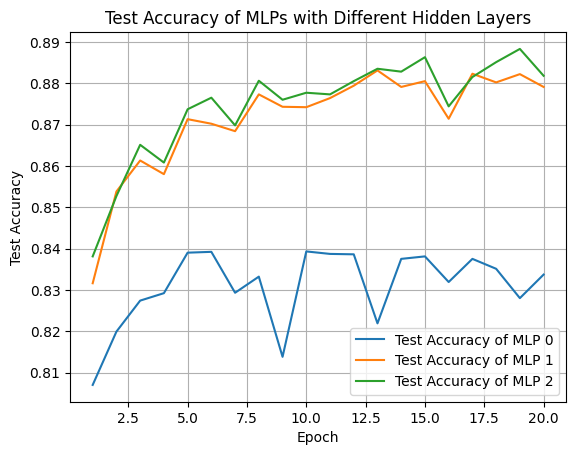

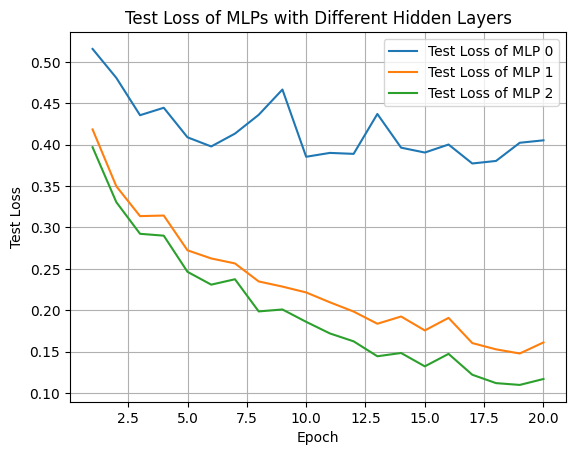

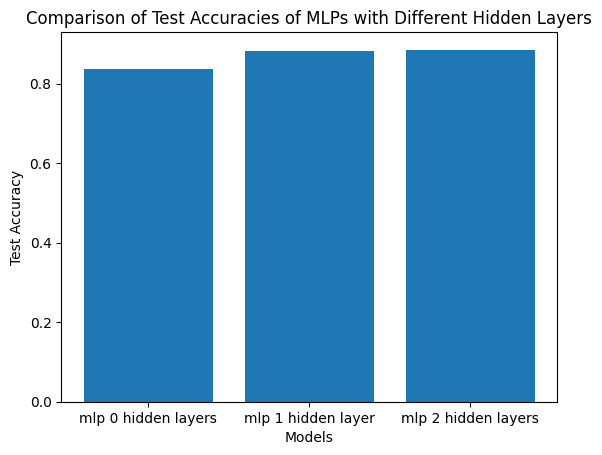

In [8]:
#Train MLP on no hidden layers
mlp_0 = MLP(activation=None, num_hidden=0, hidden_units=0)
mlp_0.fit(X_train, y_train, learning_rate=0.05, epochs=20, batch_size=64, optimizer=GradientDescent(learning_rate=0.05),X_val=X_val, y_val=y_val, X_test=X_test, y_test=y_test)

#Train MLP on 1 hidden layer
mlp_1 = MLP(activation='relu', num_hidden=1, hidden_units=256)
mlp_1.fit(X_train, y_train, learning_rate=0.05, epochs=20, batch_size=64, optimizer=GradientDescent(learning_rate=0.05),X_val=X_val, y_val=y_val, X_test=X_test, y_test=y_test)

#Train MLP on 2 hidden layers
mlp_2 = MLP(activation='relu', num_hidden=2, hidden_units=[256, 256])
mlp_2.fit(X_train, y_train, learning_rate=0.05, epochs=20, batch_size=64, optimizer=GradientDescent(learning_rate=0.05),X_val=X_val, y_val=y_val, X_test=X_test, y_test=y_test)

y0_test_pred = mlp_0.predict(X_test)
y0_test_acc = evaluate_acc(y_test, y0_test_pred)

y1_test_pred = mlp_1.predict(X_test)
y1_test_acc = evaluate_acc(y_test, y1_test_pred)

y2_test_pred = mlp_2.predict(X_test)
y2_test_acc = evaluate_acc(y_test, y2_test_pred)

#Create Plots
epoch0 = range(1, len(mlp_0.history['test_acc']) + 1)
epoch1 = range(1, len(mlp_1.history['test_acc']) + 1)
epoch2 = range(1, len(mlp_2.history['test_acc']) + 1 )

#plot mlp_0, mlp_1, mlp_2
plt.plot(epoch0, mlp_0.history['test_acc'], label='Test Accuracy of MLP 0')
plt.plot(epoch1, mlp_1.history['test_acc'], label='Test Accuracy of MLP 1')
plt.plot(epoch2, mlp_2.history['test_acc'], label='Test Accuracy of MLP 2')

plt.title('Test Accuracy of MLPs with Different Hidden Layers')
plt.xlabel('Epoch')
plt.ylabel('Test Accuracy')
plt.legend()
plt.grid(True)
plt.show()

#Plot Loss vs epochs
plt.plot(epoch0, mlp_0.history['train_loss'], label='Test Loss of MLP 0')
plt.plot(epoch1, mlp_1.history['train_loss'], label='Test Loss of MLP 1')
plt.plot(epoch2, mlp_2.history['train_loss'], label='Test Loss of MLP 2')

plt.title('Test Loss of MLPs with Different Hidden Layers')
plt.xlabel('Epoch')
plt.ylabel('Test Loss')
plt.legend()
plt.grid(True)
plt.show()

#Plot test accuracies
models = ['mlp 0 hidden layers', 'mlp 1 hidden layer', 'mlp 2 hidden layers']
test_accs = [y0_test_acc, y1_test_acc, y2_test_acc]

plt.bar(models, test_accs)
plt.title('Comparison of Test Accuracies of MLPs with Different Hidden Layers')
plt.xlabel('Models')
plt.ylabel('Test Accuracy')
plt.show()

3.2: MLP with 2 hidden layers and tanh and Leaky-ReLU activations

/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:77: RuntimeWarning: divide by zero encountered in matmul
  z.append(a[-1] @ W + b)
/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:77: RuntimeWarning: overflow encountered in matmul
  z.append(a[-1] @ W + b)
/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:77: RuntimeWarning: invalid value encountered in matmul
  z.append(a[-1] @ W + b)
/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:79: RuntimeWarning: divide by zero encountered in matmul
  probs = softmax(a[-1] @ self.weights[-1] + self.biases[-1])
/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:79: RuntimeWarning: overflow encountered in matmul
  probs = softmax(a[-1] @ self.weights[-1] + self.biases[-1])
/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:79: RuntimeWarning: invalid value encountered in mat

epoch   1 | train loss 0.4174 acc 0.8510 | val acc nan | test acc nan | 0.2s
epoch   2 | train loss 0.3488 acc 0.8736 | val acc nan | test acc nan | 0.2s
epoch   3 | train loss 0.3132 acc 0.8878 | val acc nan | test acc nan | 0.2s
epoch   4 | train loss 0.3126 acc 0.8855 | val acc nan | test acc nan | 0.2s
epoch   5 | train loss 0.2717 acc 0.9022 | val acc nan | test acc nan | 0.2s
epoch   6 | train loss 0.2583 acc 0.9062 | val acc nan | test acc nan | 0.2s
epoch   7 | train loss 0.2664 acc 0.9001 | val acc nan | test acc nan | 0.2s
epoch   8 | train loss 0.2308 acc 0.9173 | val acc nan | test acc nan | 0.2s
epoch   9 | train loss 0.2328 acc 0.9141 | val acc nan | test acc nan | 0.2s
epoch  10 | train loss 0.2146 acc 0.9215 | val acc nan | test acc nan | 0.2s
epoch  11 | train loss 0.1994 acc 0.9272 | val acc nan | test acc nan | 0.2s
epoch  12 | train loss 0.1932 acc 0.9290 | val acc nan | test acc nan | 0.2s
epoch  13 | train loss 0.1804 acc 0.9343 | val acc nan | test acc nan | 0.2s

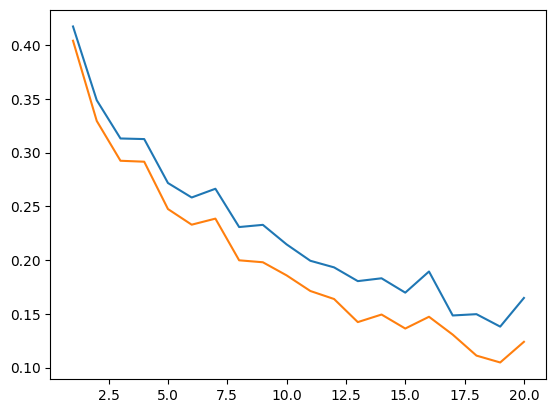

In [9]:
# MLP 2 hidden layers - tahn
mlp_32_tanh = MLP(activation='tanh', num_hidden=2, hidden_units=[256, 256])
mlp_32_tanh.fit(X_train, y_train, learning_rate=0.05, epochs=20, batch_size=64, optimizer=GradientDescent(learning_rate=0.05))
epoch_32_tanh = range(1, len(mlp_32_tanh.history['train_acc']) + 1)

# MLP 2 hidden layers - leaky reLU
mlp_32_leaky = MLP(activation='leaky_relu', num_hidden=2, hidden_units=[256, 256])
mlp_32_leaky.fit(X_train, y_train, learning_rate=0.05, epochs=20, batch_size=64, optimizer=GradientDescent(learning_rate=0.05))
epoch_32_leaky = range(1, len(mlp_32_leaky.history['train_acc']) + 1)

plt.plot(epoch_32_tanh, mlp_32_tanh.history['train_loss'], label='Test Accuracy of MLP with tanh activation')
plt.plot(epoch_32_leaky, mlp_32_leaky.history['train_loss'], label='Test Accuracy of MLP with Leaku-reLU activation')

3.3: Early stop with L1 and L2 regularization

/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:77: RuntimeWarning: divide by zero encountered in matmul
  z.append(a[-1] @ W + b)
/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:77: RuntimeWarning: overflow encountered in matmul
  z.append(a[-1] @ W + b)
/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:77: RuntimeWarning: invalid value encountered in matmul
  z.append(a[-1] @ W + b)
/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:79: RuntimeWarning: divide by zero encountered in matmul
  probs = softmax(a[-1] @ self.weights[-1] + self.biases[-1])
/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:79: RuntimeWarning: overflow encountered in matmul
  probs = softmax(a[-1] @ self.weights[-1] + self.biases[-1])
/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:79: RuntimeWarning: invalid value encountered in mat

epoch   1 | train loss 0.4014 acc 0.8552 | val acc 0.8493 | test acc 0.8366 | 0.9s
epoch   2 | train loss 0.3319 acc 0.8787 | val acc 0.8672 | test acc 0.8549 | 0.9s
epoch   3 | train loss 0.2921 acc 0.8927 | val acc 0.8791 | test acc 0.8652 | 0.9s
epoch   4 | train loss 0.2927 acc 0.8925 | val acc 0.8734 | test acc 0.8630 | 0.9s
epoch   1 | train loss 0.3978 acc 0.8569 | val acc 0.8512 | test acc 0.8383 | 0.2s
epoch   2 | train loss 0.3310 acc 0.8789 | val acc 0.8680 | test acc 0.8536 | 0.2s
epoch   3 | train loss 0.2903 acc 0.8940 | val acc 0.8784 | test acc 0.8665 | 0.2s
epoch   4 | train loss 0.2903 acc 0.8938 | val acc 0.8736 | test acc 0.8615 | 0.2s
epoch   1 | train loss 0.3971 acc 0.8573 | val acc 0.8505 | test acc 0.8381 | 0.2s
epoch   2 | train loss 0.3307 acc 0.8800 | val acc 0.8688 | test acc 0.8527 | 0.2s
epoch   3 | train loss 0.2924 acc 0.8925 | val acc 0.8786 | test acc 0.8651 | 0.2s
epoch   4 | train loss 0.2901 acc 0.8940 | val acc 0.8737 | test acc 0.8608 | 0.2s
epoc

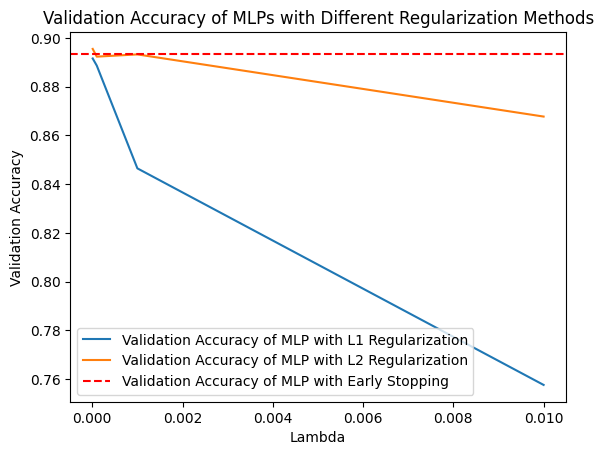

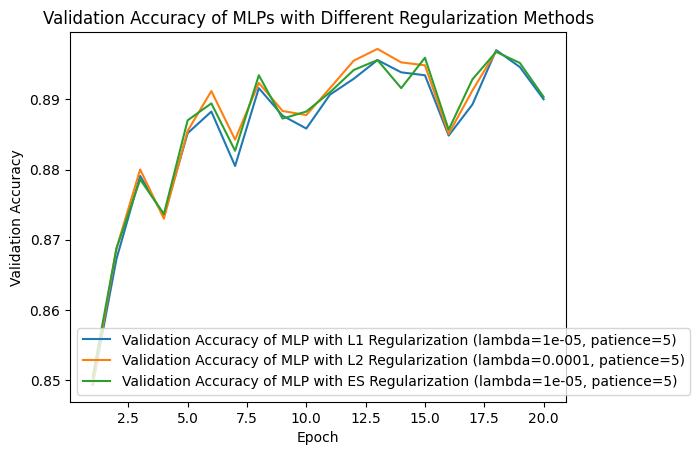

In [10]:
#use diff regularizaiton method with mlp_2 and compare the results
lambd_arr = [10**-5, 10**-4, 10**-3, 10**-2]
patience_val = [1, 3, 5]
dic = {}

for lambd in lambd_arr:
    for p in patience_val:
        #create MLP with Early stopping + L1 reg
        es_mlp_l1 = MLP(activation='relu', num_hidden=2, hidden_units=[256, 256], l1=lambd, l2=0.0)
        es_mlp_l1.fit(X_train, y_train, learning_rate=0.05, epochs=20, batch_size=64, optimizer=GradientDescent(learning_rate=0.05), X_val=X_val, y_val=y_val, X_test=X_test, y_test=y_test, es=True, patience=p)

        #create MLP with Early stopping + L2 reg
        es_mlp_l2 = MLP(activation='relu', num_hidden=2, hidden_units=[256, 256], l1=0.0, l2=lambd)
        es_mlp_l2.fit(X_train, y_train, learning_rate=0.05, epochs=20, batch_size=64, optimizer=GradientDescent(learning_rate=0.05), X_val=X_val, y_val=y_val, X_test=X_test, y_test=y_test, es=True, patience=p)

        # create MLP with Early stopping + no reg
        es_mlp = MLP(activation='relu', num_hidden=2, hidden_units=[256, 256], l1=0.0, l2=0.0)
        es_mlp.fit(X_train, y_train, learning_rate=0.05, epochs=20, batch_size=64, optimizer=GradientDescent(learning_rate=0.05), X_val=X_val, y_val=y_val, X_test=X_test, y_test=y_test, es=True, patience=p)

        dic['l1',lambd, p] = es_mlp_l1.history['val_acc']
        dic['l2',lambd, p] = es_mlp_l2.history['val_acc']
        dic['es',lambd, p] = es_mlp.history['val_acc']

#plot mlp with validation accuracies vs epoch
p = 3
l1, l2 = [],[]

for lambd in lambd_arr:
    l1.append(max(dic['l1', lambd, p]))
    l2.append(max(dic['l2', lambd, p]))

plt.plot(lambd_arr, l1, label='Validation Accuracy of MLP with L1 Regularization')
plt.plot(lambd_arr, l2, label='Validation Accuracy of MLP with L2 Regularization')

plt.axhline(max(dic['es', lambd_arr[0], p]), color='r', linestyle='--', label='Validation Accuracy of MLP with Early Stopping')

plt.xlabel('Lambda')
plt.ylabel('Validation Accuracy')
plt.title('Validation Accuracy of MLPs with Different Regularization Methods')
plt.legend()
plt.show()

#plot mlp with validation accuracies vs epoch for best lambda and patience
best_l1 = max((k for k in dic if k[0] == 'l1'), key=lambda k : max(dic[k]))
best_l2 = max((k for k in dic if k[0] == 'l2'), key=lambda k : max(dic[k]))
best_es = max((k for k in dic if k[0] == 'es'), key=lambda k : max(dic[k]))

best_lam_p_list = [best_l1, best_l2, best_es]
for best in best_lam_p_list:
    reg_type, lambd, p = best
    vals = dic[best]
    epochs = range(1, len(vals) + 1)

    plt.plot(epochs, vals, label=f'Validation Accuracy of MLP with {reg_type.upper()} Regularization (lambda={lambd}, patience={p})')

plt.title('Validation Accuracy of MLPs with Different Regularization Methods')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.show()

3.4: MLP with 2 hidden layers each having 264 units and unormalized images

In [11]:
model_34 = MLP(activation='relu', num_hidden=2, hidden_units=264)
optimizer_34 = GradientDescent(learning_rate=0.05)

model_34.fit(
    X_train_raw, y_train,
    learning_rate=0.05,
    epochs=100,
    batch_size=64,
    optimizer=optimizer_34,
    X_val=X_val_raw,
    y_val=y_val,
    X_test=X_test_raw,
    y_test=y_test,
    name='MLP Unnormalized (2x264)'
)

acc_34 = evaluate_acc(y_test, model_34.predict(X_test_raw))
print(f"Test Accuracy (Unnormalized): {acc_34:.4f}")

/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:77: RuntimeWarning: divide by zero encountered in matmul
  z.append(a[-1] @ W + b)
/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:77: RuntimeWarning: overflow encountered in matmul
  z.append(a[-1] @ W + b)
/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:77: RuntimeWarning: invalid value encountered in matmul
  z.append(a[-1] @ W + b)
/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:79: RuntimeWarning: divide by zero encountered in matmul
  probs = softmax(a[-1] @ self.weights[-1] + self.biases[-1])
/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:79: RuntimeWarning: overflow encountered in matmul
  probs = softmax(a[-1] @ self.weights[-1] + self.biases[-1])
/var/folders/t1/fwmzpg4s31x3xhdy_cdlxlgr0000gn/T/ipykernel_53413/1789601588.py:79: RuntimeWarning: invalid value encountered in mat

epoch   1 | train loss 2.3026 acc 0.0998 | val acc 0.1008 | test acc 0.1000 | 0.2s
epoch   2 | train loss 2.3026 acc 0.1011 | val acc 0.0958 | test acc 0.0999 | 0.2s
epoch   3 | train loss 2.3028 acc 0.0996 | val acc 0.1016 | test acc 0.1000 | 0.2s
epoch   4 | train loss 2.3026 acc 0.1011 | val acc 0.0958 | test acc 0.0999 | 0.2s
epoch   5 | train loss 2.3026 acc 0.1004 | val acc 0.0985 | test acc 0.1000 | 0.2s
epoch   6 | train loss 2.3028 acc 0.1001 | val acc 0.0995 | test acc 0.1000 | 0.2s
epoch   7 | train loss 2.3027 acc 0.1011 | val acc 0.0958 | test acc 0.0999 | 0.2s
epoch   8 | train loss 2.3027 acc 0.1001 | val acc 0.0995 | test acc 0.1000 | 0.2s
epoch   9 | train loss 2.3027 acc 0.1001 | val acc 0.0995 | test acc 0.1000 | 0.2s
epoch  10 | train loss 2.3026 acc 0.1011 | val acc 0.0958 | test acc 0.0999 | 0.2s
epoch  11 | train loss 2.3027 acc 0.0995 | val acc 0.1022 | test acc 0.1000 | 0.2s
epoch  12 | train loss 2.3027 acc 0.1001 | val acc 0.0995 | test acc 0.1000 | 0.2s
epoc

3.6: CNN with 2 conv layers + 1 fc hidden layer (256) + fc output

In [12]:
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
from matplotlib.ticker import MaxNLocator

def summarize(histories):
    rows = [{'model': h['name'],
             'epochs': len(h['train_acc']),
             'best epoch (val)': h['best_epoch'],
             'val acc': h['best_val_acc'],
             'test acc': h['test_acc_at_best'],
             'train acc': h['train_acc'][h['best_epoch'] - 1],
             'time / epoch (s)': np.mean(h['epoch_time']),
             'total time (s)': h['total_train_time'],
             'trainable params': h['n_trainable']} for h in histories if h is not None]
    return pd.DataFrame(rows).round(4)

SERIES_COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']

# line = train dashed = test (or val)
def plot_histories(histories, title, eval_split='test'):
    histories = [h for h in histories if h is not None]
    assert len(histories) <= len(SERIES_COLORS)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
    for h, color in zip(histories, SERIES_COLORS):
        ep = np.arange(1, len(h['train_acc']) + 1)
        for ax, metric in zip(axes, ['acc', 'loss']):
            ax.plot(ep, h[f'train_{metric}'], color=color, lw=2, label=f"{h['name']} - train")
            ax.plot(ep, h[f'{eval_split}_{metric}'], color=color, lw=2, ls='--', label=f"{h['name']} - {eval_split}")
    for ax, ylabel in zip(axes, ['accuracy', 'cross entropy loss']):
        ax.set_xlabel('epoch'); ax.set_ylabel(ylabel)
        ax.grid(True, color='#e1e0d9', lw=0.8); ax.set_axisbelow(True)
        for side in ['top', 'right']: ax.spines[side].set_visible(False)
        for side in ['left', 'bottom']: ax.spines[side].set_color('#c3c2b7')
        ax.tick_params(colors='#52514e')
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    axes[0].legend(fontsize=8, frameon=False)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


NUM_WORKERS = 2 if os.name != 'nt' else 0
PIN_MEMORY = device.type == 'cuda'
USE_AMP = device.type == 'cuda'  # mixed precision on gpu to go faster

def make_loaders(train_ds, val_ds, test_ds, batch_size=128):
    kw = dict(num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, persistent_workers=NUM_WORKERS > 0)
    return (DataLoader(train_ds, batch_size=batch_size, shuffle=True, **kw),
            DataLoader(val_ds, batch_size=512, shuffle=False, **kw),
            DataLoader(test_ds, batch_size=512, shuffle=False, **kw))

# train if optimizer is given else just eval
def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(x)
                loss = criterion(logits, y)
            if training:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * len(y)
            correct += (logits.argmax(dim=1) == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n

# adam on the trainable params only and keep the best val epoch
# epoch_time = only the training pass (with data loading and augmentation)
def train_model(make_model, loaders, epochs=10, lr=1e-3, weight_decay=0.0, name='model', verbose=True):
    set_seed()
    model = make_model().to(device)
    train_loader, val_loader, test_loader = loaders
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(params, lr=lr, weight_decay=weight_decay)
    scaler = torch.amp.GradScaler(device.type, enabled=USE_AMP)
    criterion = nn.CrossEntropyLoss()  # softmax is inside
    hist = {k: [] for k in ['train_loss', 'train_acc', 'val_loss', 'val_acc', 'test_loss', 'test_acc', 'epoch_time']}
    best_val, best_epoch, best_state = -1.0, 0, None

    for epoch in range(1, epochs + 1):
        if device.type == 'cuda': torch.cuda.synchronize()
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer, scaler)
        if device.type == 'cuda': torch.cuda.synchronize()
        hist['epoch_time'].append(time.time() - t0)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        te_loss, te_acc = run_epoch(model, test_loader, criterion)
        for k, v in zip(['train_loss', 'train_acc', 'val_loss', 'val_acc', 'test_loss', 'test_acc'],
                        [tr_loss, tr_acc, va_loss, va_acc, te_loss, te_acc]):
            hist[k].append(v)
        if va_acc > best_val:
            best_val, best_epoch = va_acc, epoch
            best_state = copy.deepcopy(model.state_dict())
        if verbose:
            print(f"[{name}] epoch {epoch:2d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
                  f"val acc {va_acc:.4f} | test acc {te_acc:.4f} | {hist['epoch_time'][-1]:.1f}s")

    model.load_state_dict(best_state)
    hist.update(name=name, best_epoch=best_epoch, best_val_acc=best_val,
                test_acc_at_best=hist['test_acc'][best_epoch - 1],
                total_train_time=sum(hist['epoch_time']),
                n_trainable=sum(p.numel() for p in params))
    return model, hist

In [13]:
# conv -> relu -> pool -> conv -> relu -> pool -> fc 256 -> relu -> fc 10
class CNN(nn.Module):
    def __init__(self, channels=(32, 64), kernel_size=3, fc_units=256, in_channels=1, img_size=28,
                 num_classes=10, dropout=0.0):
        super().__init__()
        c1, c2 = channels
        pad = kernel_size // 2
        self.features = nn.Sequential(
            nn.Conv2d(in_channels, c1, kernel_size, padding=pad), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(c1, c2, kernel_size, padding=pad), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(c2 * (img_size // 4) ** 2, fc_units), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(fc_units, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

cnn_eval_tf = transforms.Compose([transforms.ToTensor(), normalize_tf])
cnn_aug_tf = transforms.Compose(augment_ops + [transforms.ToTensor(), normalize_tf])
fm_cnn_splits = make_fmnist_splits(cnn_eval_tf, cnn_eval_tf)
fm_cnn_aug_splits = make_fmnist_splits(cnn_aug_tf, cnn_eval_tf)

print(CNN())
print("trainable params:", sum(p.numel() for p in CNN().parameters()))

CNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.0, inplace=False)
    (4): Linear(in_features=256, out_features=10, bias=True)
  )
)
trainable params: 824458


In [14]:
# small sweep on val for lr then batch size then channels (one at a time)
RUN_SWEEPS = True
SWEEP_EPOCHS = 5

best_cfg = dict(lr=1e-3, batch_size=128, channels=(32, 64))
search_space = [('lr', [3e-4, 1e-3, 3e-3]),
                ('batch_size', [64, 128, 256]),
                ('channels', [(16, 32), (32, 64), (64, 128)])]
sweep_rows, sweep_cache = [], {}

if RUN_SWEEPS:
    for key, values in search_space:
        scores = {}
        for v in values:
            cfg = {**best_cfg, key: v}
            cache_key = tuple(sorted((k, str(c)) for k, c in cfg.items()))
            if cache_key not in sweep_cache:
                _, h = train_model(lambda: CNN(channels=cfg['channels']),
                                   make_loaders(*fm_cnn_splits, batch_size=cfg['batch_size']),
                                   epochs=SWEEP_EPOCHS, lr=cfg['lr'], name=str(cfg), verbose=False)
                sweep_cache[cache_key] = h
            h = sweep_cache[cache_key]
            scores[v] = h['best_val_acc']
            sweep_rows.append({'swept': key, 'lr': cfg['lr'], 'batch size': cfg['batch_size'],
                               'channels': str(cfg['channels']), 'best val acc': round(h['best_val_acc'], 4),
                               'time / epoch (s)': round(np.mean(h['epoch_time']), 2)})
            print(sweep_rows[-1])
        best_cfg[key] = max(scores, key=scores.get)
    cnn_sweep_table = pd.DataFrame(sweep_rows)
    display(cnn_sweep_table)

print("cnn hyperparams:", best_cfg)

{'swept': 'lr', 'lr': 0.0003, 'batch size': 128, 'channels': '(32, 64)', 'best val acc': 0.9038, 'time / epoch (s)': np.float64(11.21)}
{'swept': 'lr', 'lr': 0.001, 'batch size': 128, 'channels': '(32, 64)', 'best val acc': 0.9166, 'time / epoch (s)': np.float64(10.88)}
{'swept': 'lr', 'lr': 0.003, 'batch size': 128, 'channels': '(32, 64)', 'best val acc': 0.9126, 'time / epoch (s)': np.float64(10.98)}
{'swept': 'batch_size', 'lr': 0.001, 'batch size': 64, 'channels': '(32, 64)', 'best val acc': 0.9162, 'time / epoch (s)': np.float64(12.36)}
{'swept': 'batch_size', 'lr': 0.001, 'batch size': 128, 'channels': '(32, 64)', 'best val acc': 0.9166, 'time / epoch (s)': np.float64(10.88)}
{'swept': 'batch_size', 'lr': 0.001, 'batch size': 256, 'channels': '(32, 64)', 'best val acc': 0.9107, 'time / epoch (s)': np.float64(10.53)}
{'swept': 'channels', 'lr': 0.001, 'batch size': 128, 'channels': '(16, 32)', 'best val acc': 0.9117, 'time / epoch (s)': np.float64(7.75)}
{'swept': 'channels', 'lr'

,swept,lr,batch size,channels,best val acc,time / epoch (s)
0,lr,0.0003,128,"(32, 64)",0.9038,11.21
1,lr,0.0010,128,"(32, 64)",0.9166,10.88
2,lr,0.0030,128,"(32, 64)",0.9126,10.98
3,batch_size,0.0010,64,"(32, 64)",0.9162,12.36
4,batch_size,0.0010,128,"(32, 64)",0.9166,10.88
5,batch_size,0.0010,256,"(32, 64)",0.9107,10.53
6,channels,0.0010,128,"(16, 32)",0.9117,7.75
7,channels,0.0010,128,"(32, 64)",0.9166,10.88
8,channels,0.0010,128,"(64, 128)",0.9217,18.99


cnn hyperparams: {'lr': 0.001, 'batch_size': 128, 'channels': (64, 128)}


[CNN] epoch  1 | train loss 0.4404 acc 0.8415 | val acc 0.8828 | test acc 0.8744 | 19.9s
[CNN] epoch  2 | train loss 0.2739 acc 0.8998 | val acc 0.9087 | test acc 0.9039 | 18.6s
[CNN] epoch  3 | train loss 0.2222 acc 0.9177 | val acc 0.9118 | test acc 0.9051 | 18.7s
[CNN] epoch  4 | train loss 0.1855 acc 0.9315 | val acc 0.9155 | test acc 0.9108 | 19.7s
[CNN] epoch  5 | train loss 0.1574 acc 0.9423 | val acc 0.9217 | test acc 0.9128 | 19.8s
[CNN] epoch  6 | train loss 0.1327 acc 0.9504 | val acc 0.9233 | test acc 0.9216 | 21.0s
[CNN] epoch  7 | train loss 0.1070 acc 0.9605 | val acc 0.9240 | test acc 0.9136 | 20.9s
[CNN] epoch  8 | train loss 0.0864 acc 0.9681 | val acc 0.9247 | test acc 0.9161 | 19.2s
[CNN] epoch  9 | train loss 0.0706 acc 0.9744 | val acc 0.9225 | test acc 0.9165 | 18.3s
[CNN] epoch 10 | train loss 0.0620 acc 0.9774 | val acc 0.9241 | test acc 0.9196 | 19.4s
[CNN] epoch 11 | train loss 0.0451 acc 0.9838 | val acc 0.9241 | test acc 0.9182 | 18.9s
[CNN] epoch 12 | trai

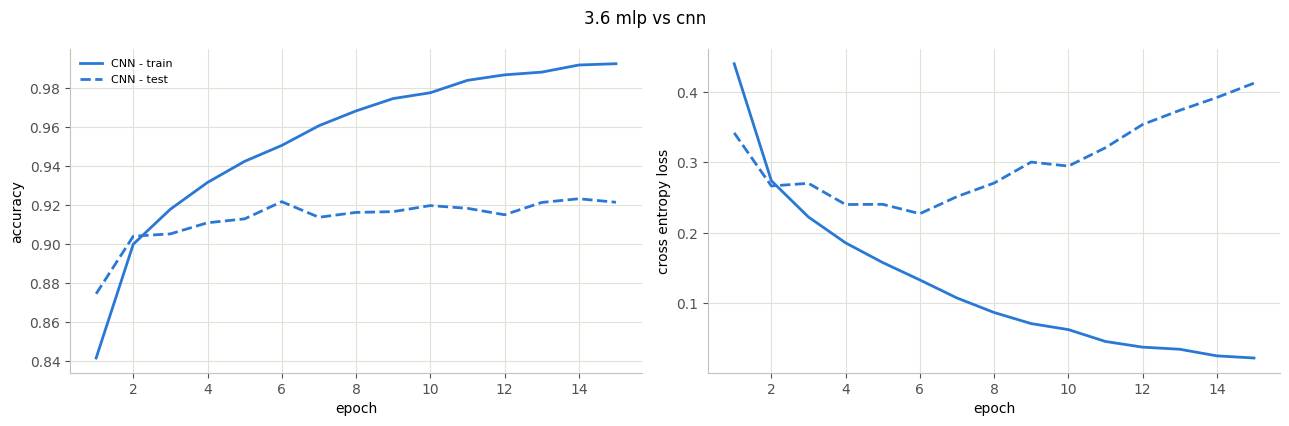

,model,epochs,best epoch (val),val acc,test acc,train acc,time / epoch (s),total time (s),trainable params
0,CNN,15,14,0.9269,0.9231,0.9916,19.3285,289.9268,1682954


In [15]:
CNN_EPOCHS = 15

cnn_model, hist_cnn = train_model(lambda: CNN(channels=best_cfg['channels']),
                                  make_loaders(*fm_cnn_splits, batch_size=best_cfg['batch_size']),
                                  epochs=CNN_EPOCHS, lr=best_cfg['lr'], name='CNN')

# hist_mlp = the 2 hidden 256 relu mlp from 3.1 (only used if it was run)
mlp_ref = globals().get('hist_mlp')
plot_histories([mlp_ref, hist_cnn], '3.6 mlp vs cnn')
display(summarize([mlp_ref, hist_cnn]))

3.7: same CNN with the augmentation from 3.5

[CNN + augmentation] epoch  1 | train loss 0.6798 acc 0.7452 | val acc 0.8412 | test acc 0.8338 | 19.8s
[CNN + augmentation] epoch  2 | train loss 0.4665 acc 0.8251 | val acc 0.8708 | test acc 0.8715 | 18.6s
[CNN + augmentation] epoch  3 | train loss 0.4033 acc 0.8502 | val acc 0.8689 | test acc 0.8649 | 18.5s
[CNN + augmentation] epoch  4 | train loss 0.3674 acc 0.8633 | val acc 0.8937 | test acc 0.8918 | 18.5s
[CNN + augmentation] epoch  5 | train loss 0.3514 acc 0.8689 | val acc 0.8992 | test acc 0.8965 | 18.5s
[CNN + augmentation] epoch  6 | train loss 0.3271 acc 0.8782 | val acc 0.9039 | test acc 0.9040 | 18.5s
[CNN + augmentation] epoch  7 | train loss 0.3177 acc 0.8818 | val acc 0.9062 | test acc 0.9032 | 18.7s
[CNN + augmentation] epoch  8 | train loss 0.3049 acc 0.8864 | val acc 0.9096 | test acc 0.9019 | 18.6s
[CNN + augmentation] epoch  9 | train loss 0.2933 acc 0.8914 | val acc 0.9115 | test acc 0.9067 | 18.6s
[CNN + augmentation] epoch 10 | train loss 0.2894 acc 0.8916 | v

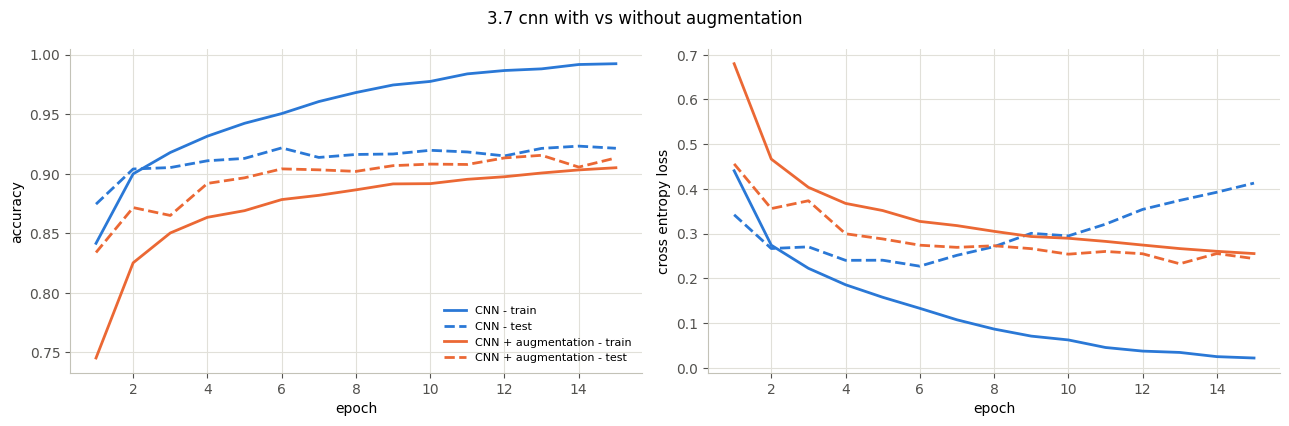

,model,epochs,best epoch (val),val acc,test acc,train acc,time / epoch (s),total time (s),trainable params
0,CNN,15,14,0.9269,0.9231,0.9916,19.3285,289.9268,1682954
1,CNN + augmentation,15,13,0.9221,0.9154,0.9005,18.9437,284.1549,1682954


one epoch with augmentation is 0.98x slower


In [16]:
cnn_aug_model, hist_cnn_aug = train_model(lambda: CNN(channels=best_cfg['channels']),
                                          make_loaders(*fm_cnn_aug_splits, batch_size=best_cfg['batch_size']),
                                          epochs=CNN_EPOCHS, lr=best_cfg['lr'], name='CNN + augmentation')

plot_histories([hist_cnn, hist_cnn_aug], '3.7 cnn with vs without augmentation')
display(summarize([hist_cnn, hist_cnn_aug]))
slowdown = np.mean(hist_cnn_aug['epoch_time']) / np.mean(hist_cnn['epoch_time'])
print(f"one epoch with augmentation is {slowdown:.2f}x slower")

3.8: pretrained resnet18 with frozen conv layers + new fc layers (with augmentation)

In [17]:
from torchvision.models import resnet18, ResNet18_Weights

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

# resnet18 has only one fc so we remove it and put our head after the avg pool (512 features)
class PretrainedResNet(nn.Module):
    def __init__(self, head_hidden=(256,), num_classes=10, img_size=96, dropout=0.3, pretrained=True):
        super().__init__()
        self.backbone = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
        feat_dim = self.backbone.fc.in_features
        self.backbone.fc = nn.Identity()
        for p in self.backbone.parameters():
            p.requires_grad = False  # freeze all conv layers

        layers, d = [], feat_dim
        for h in head_hidden:
            layers += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(dropout)]
            d = h
        layers.append(nn.Linear(d, num_classes))
        self.head = nn.Sequential(*layers)

        self.img_size = img_size
        self.register_buffer('im_mean', torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1))
        self.register_buffer('im_std', torch.tensor(IMAGENET_STD).view(1, 3, 1, 1))

    def train(self, mode=True):
        super().train(mode)
        self.backbone.eval()  # batchnorm stays frozen too
        return self

    # gray to 3 channels then resize on gpu then imagenet normalization
    def forward(self, x):
        if x.shape[1] == 1:
            x = x.expand(-1, 3, -1, -1)
        x = F.interpolate(x, size=(self.img_size, self.img_size), mode='bilinear', align_corners=False)
        x = (x - self.im_mean) / self.im_std
        with torch.no_grad():
            feats = self.backbone(x)
        return self.head(feats)

IMG_SIZE = 96
PRE_BATCH = 128
PRE_LR = 1e-3
HEAD_EPOCHS = 5
PRE_EPOCHS = 10

pre_train_tf = transforms.Compose(augment_ops + [transforms.ToTensor()])
pre_eval_tf = transforms.ToTensor()
fm_pre_loaders = make_loaders(*make_fmnist_splits(pre_train_tf, pre_eval_tf), batch_size=PRE_BATCH)

In [ ]:
# how many fc layers in the head (pick on val)
head_configs = {
    '1 FC (512-10)': (),
    '2 FC (512-256-10)': (256,),
    '3 FC (512-512-256-10)': (512, 256),
    '4 FC (512-1024-512-256-10)': (1024, 512, 256),
}
head_hists = {}
for label, hidden in head_configs.items():
    _, head_hists[label] = train_model(lambda: PretrainedResNet(hidden, img_size=IMG_SIZE), fm_pre_loaders,
                                       epochs=HEAD_EPOCHS, lr=PRE_LR, name=label, verbose=False)
    print(f"{label}: best val acc = {head_hists[label]['best_val_acc']:.4f}")

display(summarize(head_hists.values()))
plot_histories(list(head_hists.values()), '3.8 number of fc layers (train vs val)', eval_split='val')

best_head_label = max(head_hists, key=lambda k: head_hists[k]['best_val_acc'])
best_head = head_configs[best_head_label]
print("chosen head:", best_head_label)

In [ ]:
# extra: does the image size we give to the resnet matter
RUN_RESOLUTION_STUDY = True
RES_EPOCHS = 3
if RUN_RESOLUTION_STUDY:
    res_hists = []
    for size in [32, 64, 96, 160]:
        _, h = train_model(lambda: PretrainedResNet(best_head, img_size=size), fm_pre_loaders,
                           epochs=RES_EPOCHS, lr=PRE_LR, name=f'{size}x{size}', verbose=False)
        res_hists.append(h)
        print(f"{size}px: best val acc = {h['best_val_acc']:.4f} {np.mean(h['epoch_time']):.1f}s / epoch")
    display(summarize(res_hists))

32px: best val acc = 0.8136 11.9s / epoch
64px: best val acc = 0.8509 11.8s / epoch
96px: best val acc = 0.8556 11.4s / epoch
160px: best val acc = 0.8717 13.3s / epoch


,model,epochs,best epoch (val),val acc,test acc,train acc,time / epoch (s),total time (s),trainable params
0,32x32,3,3,0.8136,0.8114,0.7831,11.8511,35.5532,133898
1,64x64,3,3,0.8509,0.8466,0.8180,11.8464,35.5391,133898
2,96x96,3,3,0.8556,0.8508,0.8276,11.3737,34.1211,133898
3,160x160,3,3,0.8717,0.8672,0.8478,13.3116,39.9349,133898


[resnet18 frozen + 2 FC (512-256-10)] epoch  1 | train loss 0.6339 acc 0.7737 | val acc 0.8413 | test acc 0.8369 | 11.7s
[resnet18 frozen + 2 FC (512-256-10)] epoch  2 | train loss 0.4941 acc 0.8188 | val acc 0.8535 | test acc 0.8480 | 11.8s
[resnet18 frozen + 2 FC (512-256-10)] epoch  3 | train loss 0.4647 acc 0.8294 | val acc 0.8596 | test acc 0.8601 | 11.7s
[resnet18 frozen + 2 FC (512-256-10)] epoch  4 | train loss 0.4469 acc 0.8348 | val acc 0.8601 | test acc 0.8599 | 11.9s
[resnet18 frozen + 2 FC (512-256-10)] epoch  5 | train loss 0.4406 acc 0.8373 | val acc 0.8636 | test acc 0.8617 | 11.6s
[resnet18 frozen + 2 FC (512-256-10)] epoch  6 | train loss 0.4304 acc 0.8398 | val acc 0.8674 | test acc 0.8648 | 11.8s
[resnet18 frozen + 2 FC (512-256-10)] epoch  7 | train loss 0.4258 acc 0.8414 | val acc 0.8714 | test acc 0.8680 | 11.5s
[resnet18 frozen + 2 FC (512-256-10)] epoch  8 | train loss 0.4159 acc 0.8475 | val acc 0.8680 | test acc 0.8687 | 11.1s
[resnet18 frozen + 2 FC (512-256

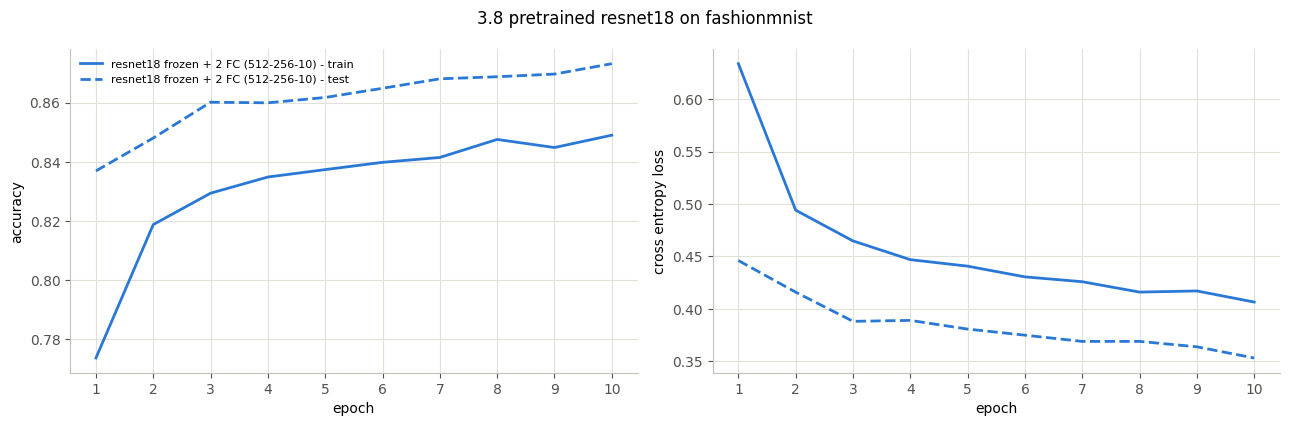

,model,epochs,best epoch (val),val acc,test acc,train acc,time / epoch (s),total time (s),trainable params
0,CNN + augmentation,15,13,0.9225,0.9151,0.9009,15.1630,227.4448,1682954
1,resnet18 frozen + 2 FC (512-256-10),10,9,0.8746,0.8696,0.8448,11.5487,115.4873,133898


In [ ]:
pre_model, hist_pre = train_model(lambda: PretrainedResNet(best_head, img_size=IMG_SIZE), fm_pre_loaders,
                                  epochs=PRE_EPOCHS, lr=PRE_LR, name=f'resnet18 frozen + {best_head_label}')

plot_histories([hist_pre], '3.8 pretrained resnet18 on fashionmnist')
# hist_mlp_q5 = the mlp from 3.5 (only used if it was run)
display(summarize([globals().get('hist_mlp_q5'), hist_cnn_aug, hist_pre]))

3.9: same pretrained model on cifar10

In [ ]:
cifar_raw = datasets.CIFAR10(DATA_ROOT, train=True, download=True)
cifar_train_idx, cifar_val_idx = split_indices(len(cifar_raw))
cifar_mean = tuple((cifar_raw.data[cifar_train_idx] / 255.0).mean(axis=(0, 1, 2)))
cifar_std = tuple((cifar_raw.data[cifar_train_idx] / 255.0).std(axis=(0, 1, 2)))
print(f"cifar train: {len(cifar_train_idx)} val: {len(cifar_val_idx)}")

# usual cifar augmentation (crop + flip)
cifar_aug_ops = [transforms.RandomCrop(32, padding=4), transforms.RandomHorizontalFlip()]

def make_cifar_splits(train_transform, eval_transform):
    train_ds = datasets.CIFAR10(DATA_ROOT, train=True, download=True, transform=train_transform)
    eval_ds = datasets.CIFAR10(DATA_ROOT, train=True, download=True, transform=eval_transform)
    test_ds = datasets.CIFAR10(DATA_ROOT, train=False, download=True, transform=eval_transform)
    return Subset(train_ds, cifar_train_idx), Subset(eval_ds, cifar_val_idx), test_ds

cifar_pre_loaders = make_loaders(*make_cifar_splits(transforms.Compose(cifar_aug_ops + [transforms.ToTensor()]),
                                                    transforms.ToTensor()), batch_size=PRE_BATCH)
cifar_norm = transforms.Normalize(cifar_mean, cifar_std)
cifar_cnn_loaders = make_loaders(*make_cifar_splits(transforms.Compose(cifar_aug_ops + [transforms.ToTensor(), cifar_norm]),
                                                    transforms.Compose([transforms.ToTensor(), cifar_norm])),
                                 batch_size=best_cfg['batch_size'])

100%|██████████| 170M/170M [05:11<00:00, 548kB/s] 


cifar train: 40000 val: 10000


[cifar10: resnet18 frozen] epoch  1 | train loss 0.7918 acc 0.7244 | val acc 0.7962 | test acc 0.8016 | 10.5s
[cifar10: resnet18 frozen] epoch  2 | train loss 0.6358 acc 0.7778 | val acc 0.8109 | test acc 0.8123 | 10.3s
[cifar10: resnet18 frozen] epoch  3 | train loss 0.6039 acc 0.7898 | val acc 0.8126 | test acc 0.8169 | 10.4s
[cifar10: resnet18 frozen] epoch  4 | train loss 0.5833 acc 0.7944 | val acc 0.8171 | test acc 0.8186 | 10.3s
[cifar10: resnet18 frozen] epoch  5 | train loss 0.5672 acc 0.8015 | val acc 0.8276 | test acc 0.8311 | 10.4s
[cifar10: resnet18 frozen] epoch  6 | train loss 0.5511 acc 0.8060 | val acc 0.8233 | test acc 0.8278 | 10.3s
[cifar10: resnet18 frozen] epoch  7 | train loss 0.5473 acc 0.8079 | val acc 0.8321 | test acc 0.8330 | 10.2s
[cifar10: resnet18 frozen] epoch  8 | train loss 0.5404 acc 0.8093 | val acc 0.8323 | test acc 0.8366 | 10.4s
[cifar10: resnet18 frozen] epoch  9 | train loss 0.5285 acc 0.8123 | val acc 0.8267 | test acc 0.8324 | 10.0s
[cifar10: 

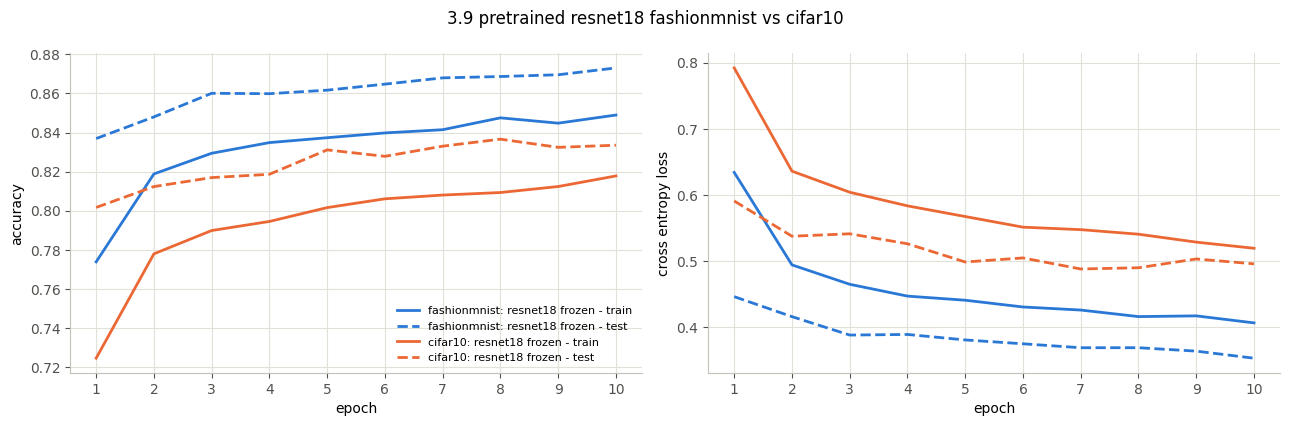

,model,epochs,best epoch (val),val acc,test acc,train acc,time / epoch (s),total time (s),trainable params
0,fashionmnist: resnet18 frozen,10,9,0.8746,0.8696,0.8448,11.5487,115.4873,133898
1,fashionmnist: cnn from scratch + aug,15,13,0.9225,0.9151,0.9009,15.1630,227.4448,1682954
2,cifar10: resnet18 frozen,10,8,0.8323,0.8366,0.8092,10.2622,102.6216,133898
3,cifar10: cnn from scratch + aug,15,13,0.7404,0.7407,0.7278,12.4379,186.5684,2175626


pretrained - from scratch: fashionmnist -0.0455 cifar10 +0.0959


In [ ]:
# also train the cnn from scratch on cifar to compare
_, hist_pre_cifar = train_model(lambda: PretrainedResNet(best_head, img_size=IMG_SIZE), cifar_pre_loaders,
                                epochs=PRE_EPOCHS, lr=PRE_LR, name='cifar10: resnet18 frozen')
_, hist_cnn_cifar = train_model(lambda: CNN(channels=best_cfg['channels'], in_channels=3, img_size=32), cifar_cnn_loaders,
                                epochs=CNN_EPOCHS, lr=best_cfg['lr'], name='cifar10: cnn from scratch + aug')

hist_pre_fm = dict(hist_pre, name='fashionmnist: resnet18 frozen')
hist_cnn_fm = dict(hist_cnn_aug, name='fashionmnist: cnn from scratch + aug')
plot_histories([hist_pre_fm, hist_pre_cifar], '3.9 pretrained resnet18 fashionmnist vs cifar10')
display(summarize([hist_pre_fm, hist_cnn_fm, hist_pre_cifar, hist_cnn_cifar]))

gain_fm = hist_pre_fm['test_acc_at_best'] - hist_cnn_fm['test_acc_at_best']
gain_cifar = hist_pre_cifar['test_acc_at_best'] - hist_cnn_cifar['test_acc_at_best']
print(f"pretrained - from scratch: fashionmnist {gain_fm:+.4f} cifar10 {gain_cifar:+.4f}")

3.10: summary of all models

,model,epochs,best epoch (val),val acc,test acc,train acc,time / epoch (s),total time (s),trainable params
0,CNN,15,15,0.9265,0.9198,0.9908,9.3621,140.4311,1682954
1,CNN + augmentation,15,13,0.9225,0.9151,0.9009,15.1630,227.4448,1682954
2,resnet18 frozen + 2 FC (512-256-10),10,9,0.8746,0.8696,0.8448,11.5487,115.4873,133898
3,cifar10: resnet18 frozen,10,8,0.8323,0.8366,0.8092,10.2622,102.6216,133898
4,cifar10: cnn from scratch + aug,15,13,0.7404,0.7407,0.7278,12.4379,186.5684,2175626


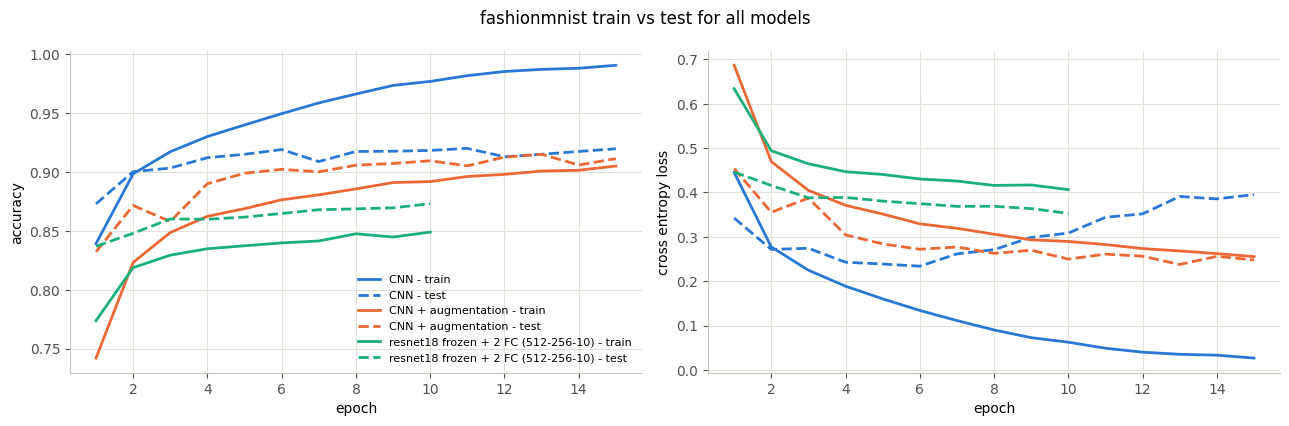

In [ ]:
# mlp results are added only if 3.1 and 3.5 were run
display(summarize([globals().get('hist_mlp'), globals().get('hist_mlp_q5'), hist_cnn, hist_cnn_aug,
                   hist_pre, hist_pre_cifar, hist_cnn_cifar]))
plot_histories([globals().get('hist_mlp'), hist_cnn, hist_cnn_aug, hist_pre], 'fashionmnist train vs test for all models')

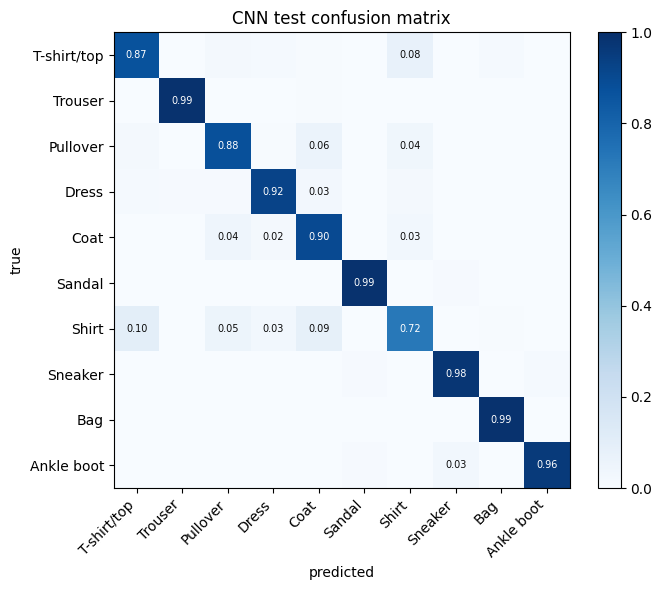

In [ ]:
# extra: confusion matrix of the best cnn on test
from sklearn.metrics import confusion_matrix

def predict_loader(model, loader):
    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for x, y in loader:
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                preds.append(model(x.to(device)).argmax(1).cpu())
            labels.append(y)
    return torch.cat(labels).numpy(), torch.cat(preds).numpy()

fm_models = {'CNN': (cnn_model, hist_cnn), 'CNN + augmentation': (cnn_aug_model, hist_cnn_aug)}
best_name = max(fm_models, key=lambda k: fm_models[k][1]['best_val_acc'])
y_true_, y_pred_ = predict_loader(fm_models[best_name][0], DataLoader(fm_cnn_splits[2], batch_size=512))
cm = confusion_matrix(y_true_, y_pred_, normalize='true')

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(10)); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha='right')
ax.set_yticks(range(10)); ax.set_yticklabels(CLASS_NAMES)
for i in range(10):
    for j in range(10):
        if cm[i, j] >= 0.02:
            ax.text(j, i, f"{cm[i, j]:.2f}", ha='center', va='center', fontsize=7,
                    color='white' if cm[i, j] > 0.5 else '#0b0b0b')
ax.set_xlabel('predicted'); ax.set_ylabel('true')
ax.set_title(f'{best_name} test confusion matrix')
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
plt.show()